In [19]:
import matplotlib.pyplot as plt  # type: ignore
from pyspark.sql import SparkSession  # type: ignore

### 1. SparkSessionの初期化（Cassandra接続設定を含む）

In [20]:
spark = (
    SparkSession.builder.appName("Jupyter-Visualizer")
    .config("spark.cassandra.connection.host", "cassandra")
    .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .getOrCreate()
)

print("Spark Version:", spark.version)
print("Spark Config Packages:", spark.conf.get("spark.jars.packages", "Not Set"))

Spark Version: 3.5.0
Spark Config Packages: com.datastax.spark:spark-cassandra-connector_2.12:3.5.1


### 2. Cassandraから集計済みテーブル（sensor_averages）を読み込む

In [25]:
# CassandraのテーブルからデータをDataFrameとして読み込む
df_avg = (
    spark.read.format("org.apache.spark.sql.cassandra").options(table="sensor_averages", keyspace="iot_keyspace").load()
)

df_avg.printSchema()

root
 |-- sensor_id: string (nullable = false)
 |-- window_start: timestamp (nullable = true)
 |-- avg_temperature: double (nullable = true)
 |-- window_end: timestamp (nullable = true)



### 3. Pandas DataFrameに変換してローカルメモリに展開（可視化のため）

In [26]:
pdf = df_avg.toPandas()

### 4. センサーごとの温度変化を時系列でプロット

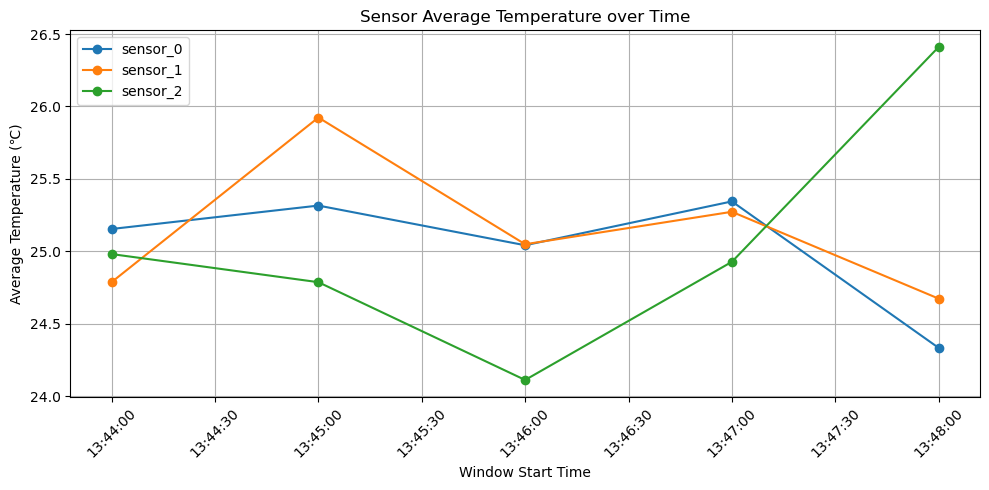

In [23]:
plt.figure(figsize=(10, 5))
for sensor_id, group in pdf.groupby("sensor_id"):
    plt.plot(group["window_start"], group["avg_temperature"], marker="o", label=sensor_id)

plt.title("Sensor Average Temperature over Time")
plt.xlabel("Window Start Time")
plt.ylabel("Average Temperature (℃)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()